# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Novri Faudzan Pratama
- NIM   : 241011401418
- Kelas : Reg C 

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [3]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#NIM : 241011401418
RANDOM_STATE = 18    # isi dengan 2 digit terakhir NIM Anda

In [4]:
# Salin fungsi train_test_split dari materi di sini

def train_test_split(X, y, test_size=0.2, random_state=18):
    np.random.seed(random_state)

    # Mengacak indeks data
    indices = np.random.permutation(len(X))

    # Menentukan jumlah data testing
    n_test = int(np.ceil(len(X) * test_size))

    # Membagi indeks training dan testing
    test_indices = indices[:n_test]
    train_indices = indices[n_test:]

    # Membagi data fitur dan target
    X_train = X[train_indices]
    X_test = X[test_indices]
    y_train = y[train_indices]
    y_test = y[test_indices]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Bentuk X: (40, 1)
Bentuk y: (40,)


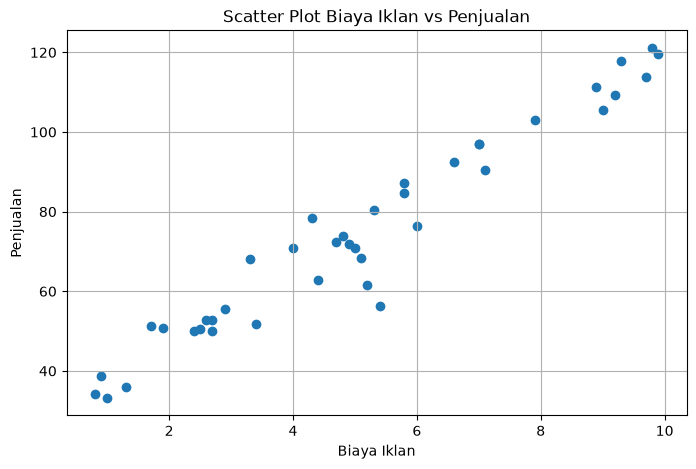

In [5]:
# Jawaban A1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Membaca dataset CSV
if os.path.exists("Ads_Data.csv"):
    ads = pd.read_csv("Ads_Data.csv")
else:
    ads = pd.read_csv("Ads_Data(1).csv")

# Menampilkan 5 data pertama
display(ads.head())

# Menampilkan jumlah baris data
print("Jumlah baris data:", len(ads))

# 2. Memisahkan fitur (X) dan target (y)
X = ads[["BiayaIklan"]].to_numpy()
y = ads["Penjualan"].to_numpy()

# Memastikan X berbentuk 2 dimensi (n, 1)
print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)

# 3. Membuat scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], y)
plt.title("Scatter Plot Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan")
plt.ylabel("Penjualan")
plt.grid(True)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [ ]:
# Jawaban A2

# Membagi data menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

# Menampilkan bentuk setiap data
print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test :", y_test.shape)

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [ ]:
# Jawaban A3

# Menambahkan kolom 1 untuk menghitung intercept
X_train_bias = np.c_[np.ones(X_train.shape[0]), X_train]

# Menghitung koefisien menggunakan Normal Equation
theta = np.linalg.pinv(X_train_bias.T @ X_train_bias) @ X_train_bias.T @ y_train

# Memisahkan intercept dan koefisien
b = theta[0]
m = theta[1]

# Menampilkan hasil
print("Intercept (b):", b)
print("Koefisien (m):", m)
print(f"Persamaan regresi: ŷ = {b:.4f} + {m:.4f}X")

Intercept (b): 29.324221482434798
Koefisien (m): 9.005114151035892
Persamaan regresi: ŷ = 29.3242 + 9.0051X


**Jawaban A3 (interpretasi):**

Model Linear Regression dilatih menggunakan metode Normal Equation untuk mendapatkan nilai intercept dan koefisien. Intercept menunjukkan perkiraan penjualan ketika biaya iklan bernilai nol, sedangkan koefisien menunjukkan perubahan penjualan setiap biaya iklan naik 1 juta rupiah. Jika nilai koefisien positif, berarti penjualan cenderung meningkat saat biaya iklan bertambah. Sebaliknya, jika nilainya negatif, penjualan cenderung menurun.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [10]:
# Jawaban A4

# Fungsi untuk menghitung metrik evaluasi
def hitung_mae(y_asli, y_prediksi):
    return np.mean(np.abs(y_asli - y_prediksi))

def hitung_mse(y_asli, y_prediksi):
    return np.mean((y_asli - y_prediksi) ** 2)

def hitung_rmse(y_asli, y_prediksi):
    return np.sqrt(hitung_mse(y_asli, y_prediksi))

def hitung_r2(y_asli, y_prediksi):
    ss_res = np.sum((y_asli - y_prediksi) ** 2)
    ss_tot = np.sum((y_asli - np.mean(y_asli)) ** 2)

    if ss_tot == 0:
        return np.nan

    return 1 - (ss_res / ss_tot)


# Prediksi data training dan testing
y_train_pred = b + m * X_train[:, 0]
y_test_pred = b + m * X_test[:, 0]

# Menghitung metrik evaluasi
hasil_evaluasi = pd.DataFrame({
    "Data": ["Training", "Testing"],
    "MAE": [
        hitung_mae(y_train, y_train_pred),
        hitung_mae(y_test, y_test_pred)
    ],
    "MSE": [
        hitung_mse(y_train, y_train_pred),
        hitung_mse(y_test, y_test_pred)
    ],
    "RMSE": [
        hitung_rmse(y_train, y_train_pred),
        hitung_rmse(y_test, y_test_pred)
    ],
    "R2": [
        hitung_r2(y_train, y_train_pred),
        hitung_r2(y_test, y_test_pred)
    ]
})

display(hasil_evaluasi.round(4))

,Data,MAE,MSE,RMSE,R2
0,Training,4.0424,31.9135,5.6492,0.9556
1,Testing,6.3949,54.5504,7.3858,0.8152


**Jawaban A4 (analisis):**

Berdasarkan hasil evaluasi, MAE, MSE, dan RMSE digunakan untuk melihat seberapa besar kesalahan prediksi model. Semakin kecil nilainya, berarti hasil prediksi semakin mendekati nilai penjualan sebenarnya. Sementara itu, nilai R² digunakan untuk melihat seberapa baik model menjelaskan perubahan penjualan berdasarkan biaya iklan. Nilai R² yang mendekati 1 menunjukkan model yang lebih baik, sedangkan nilai yang mendekati 0 menunjukkan bahwa kemampuan model dalam menjelaskan data masih terbatas. Untuk mengetahui apakah model sudah cukup baik, hasil evaluasi data training perlu dibandingkan dengan data testing. Jika hasil testing tidak jauh berbeda dari training dan nilai kesalahannya kecil, model dapat dikatakan memiliki kinerja yang cukup baik. Kesimpulan akhirnya perlu disesuaikan dengan angka hasil evaluasi yang diperoleh.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*


Learning rate: 0.001
Intercept: 26.950690637533285
Koefisien: 9.360907016624056
MSE akhir: 33.322760173740825

Learning rate: 0.02
Intercept: 29.32422148243435
Koefisien: 9.005114151035954
MSE akhir: 31.913528653150472

Learning rate: 0.1
Intercept: nan
Koefisien: nan
MSE akhir: nan

Hasil Normal Equation (A3)
Intercept: 29.324221482434798
Koefisien: 9.005114151035892


c:\Users\novri faudzan\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


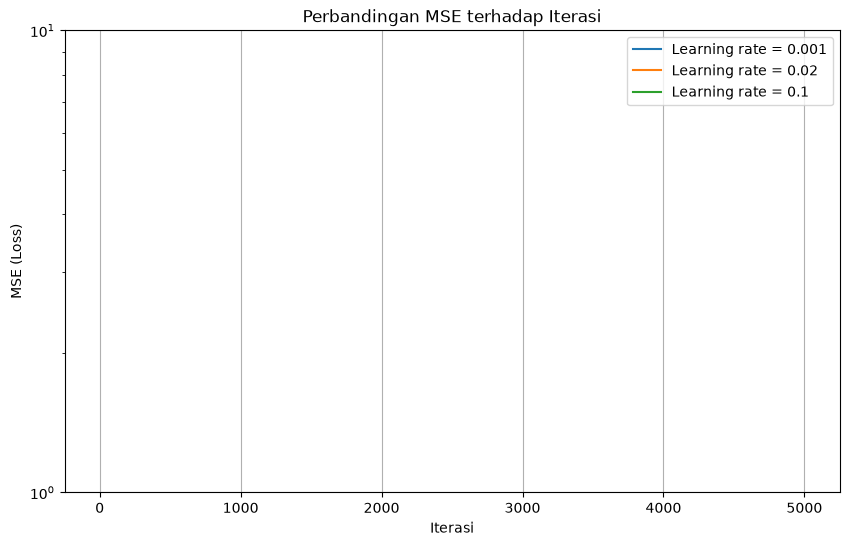

In [11]:
# Jawaban A5

def LinearRegressionGD(X, y, learning_rate=0.01, n_iterations=5000):
    # Menambahkan kolom 1 untuk intercept
    X_bias = np.c_[np.ones(X.shape[0]), X]

    # Inisialisasi parameter
    theta = np.zeros(X_bias.shape[1])
    losses = []

    # Proses Gradient Descent
    for iteration in range(n_iterations):
        y_pred = X_bias @ theta
        error = y_pred - y

        # Menghitung MSE
        mse = np.mean(error ** 2)
        losses.append(mse)

        # Menghitung gradien
        gradients = (2 / len(y)) * (X_bias.T @ error)

        # Memperbarui parameter
        with np.errstate(over='ignore', invalid='ignore'):
            theta = theta - learning_rate * gradients

    return theta[0], theta[1], losses


# Menguji tiga nilai learning rate
learning_rates = [0.001, 0.02, 0.1]
hasil_gd = {}

for lr in learning_rates:
    with np.errstate(over='ignore', invalid='ignore'):
        b_gd, m_gd, losses = LinearRegressionGD(
            X_train, y_train,
            learning_rate=lr,
            n_iterations=5000
        )

    hasil_gd[lr] = {
        "intercept": b_gd,
        "koefisien": m_gd,
        "losses": losses
    }

    print(f"\nLearning rate: {lr}")
    print("Intercept:", b_gd)
    print("Koefisien:", m_gd)
    print("MSE akhir:", losses[-1])


# Membandingkan dengan Normal Equation (A3)
print("\nHasil Normal Equation (A3)")
print("Intercept:", b)
print("Koefisien:", m)


# Membuat grafik loss terhadap iterasi
plt.figure(figsize=(10, 6))

for lr in learning_rates:
    losses = np.array(hasil_gd[lr]["losses"])
    losses[~np.isfinite(losses)] = np.nan

    plt.plot(
        range(1, len(losses) + 1),
        losses,
        label=f"Learning rate = {lr}"
    )

plt.title("Perbandingan MSE terhadap Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("MSE (Loss)")
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.show()


**Jawaban A5 (analisis):**

Pada percobaan ini, Gradient Descent menggunakan tiga nilai learning rate, yaitu 0.001, 0.02, dan 0.1, dengan 5000 iterasi. Learning rate 0.001 biasanya membutuhkan waktu lebih lama untuk mendapatkan hasil yang baik karena perubahan parameternya kecil. Learning rate 0.02 bisa menjadi pilihan yang baik jika nilai kesalahannya turun dengan stabil. Sementara itu, learning rate 0.1 bisa membuat proses perhitungan tidak stabil jika nilainya terlalu besar, sehingga kesalahan justru meningkat atau hasilnya tidak bisa dihitung dengan baik. Jika muncul peringatan overflow, artinya nilai perhitungan terlalu besar. Hasil dari ketiga learning rate kemudian dibandingkan dengan metode Normal Equation untuk melihat apakah nilai intercept dan koefisiennya mendekati hasil yang sama. Dari grafik loss dan hasil perhitungan, kita bisa mengetahui learning rate mana yang paling lambat, paling stabil, atau gagal mendapatkan hasil yang baik.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

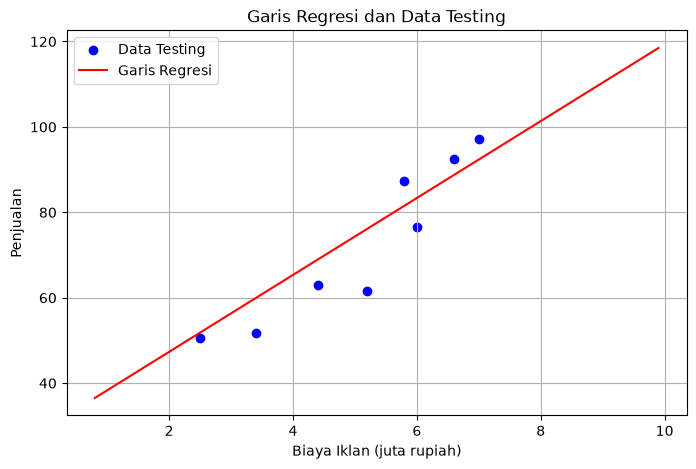

,Biaya Iklan (juta rupiah),Prediksi Penjualan
0,4.5,69.8472
1,7.0,92.3600
2,12.0,137.3856


Biaya iklan minimum: 0.8
Biaya iklan maksimum: 9.9


In [12]:
# Jawaban A6

# 1. Membuat grafik data testing dan garis regresi
plt.figure(figsize=(8, 5))

plt.scatter(
    X_test[:, 0], y_test,
    color="blue",
    label="Data Testing"
)

# Membuat garis regresi dari model A3
x_garis = np.linspace(
    X.min(), X.max(), 100
).reshape(-1, 1)

y_garis = b + m * x_garis[:, 0]

plt.plot(
    x_garis[:, 0], y_garis,
    color="red",
    label="Garis Regresi"
)

plt.title("Garis Regresi dan Data Testing")
plt.xlabel("Biaya Iklan (juta rupiah)")
plt.ylabel("Penjualan")
plt.legend()
plt.grid(True)
plt.show()


# 2. Memprediksi penjualan
biaya_baru = np.array([4.5, 7, 12])
prediksi_penjualan = b + m * biaya_baru

hasil_prediksi = pd.DataFrame({
    "Biaya Iklan (juta rupiah)": biaya_baru,
    "Prediksi Penjualan": prediksi_penjualan
})

display(hasil_prediksi.round(4))


# 3. Menampilkan rentang biaya iklan pada dataset
print("Biaya iklan minimum:", X.min())
print("Biaya iklan maksimum:", X.max())

**Jawaban A6 (analisis):**

Dari grafik tersebut, bisa dilihat hubungan antara biaya iklan dan penjualan berdasarkan data testing. Model juga digunakan untuk memperkirakan penjualan jika biaya iklan sebesar 4,5 juta, 7 juta, dan 12 juta rupiah. Namun, prediksi untuk biaya iklan 12 juta perlu lebih hati-hati jika nilainya berada di luar rentang data yang tersedia. Hal ini karena model belum memiliki contoh data pada biaya iklan sebesar itu, sehingga hasil prediksinya belum tentu sesuai dengan kenyataan. Jadi, hasil prediksi bisa dijadikan gambaran awal, tetapi belum tentu akurat dan sebaiknya didukung dengan data tambahan.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah email berdasarkan kategori:
Spam
Bukan Spam    35
Spam          25
Name: count, dtype: int64

Shape X: (60, 2)
Shape y: (60,)


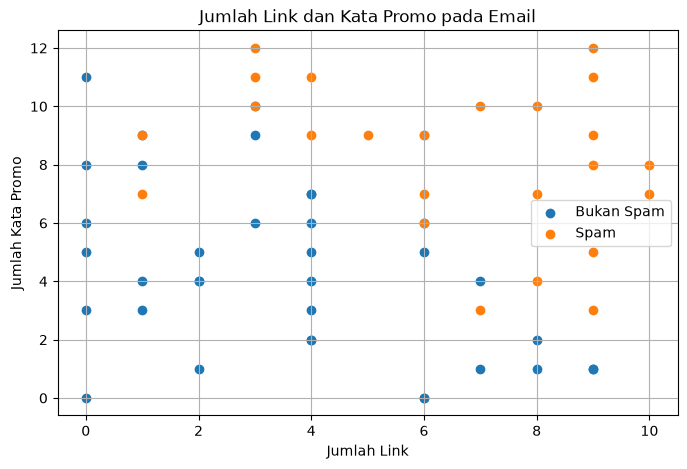

In [13]:
# Jawaban B1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Membaca dataset Email
if os.path.exists("Email_Data.csv"):
    email = pd.read_csv("Email_Data.csv")
else:
    email = pd.read_csv("Email_Data(1).csv")

# Menampilkan 5 data pertama
display(email.head())

# Menghitung jumlah email Spam dan Bukan Spam
print("Jumlah email berdasarkan kategori:")
print(email["Spam"].value_counts().rename(
    index={0: "Bukan Spam", 1: "Spam"}
))

# 2. Memisahkan fitur X dan target y
X_email = email[["JumlahLink", "KataPromo"]].to_numpy()
y_email = email["Spam"].to_numpy()

print("\nShape X:", X_email.shape)
print("Shape y:", y_email.shape)

# 3. Membuat scatter plot
plt.figure(figsize=(8, 5))

for kelas, label in [(0, "Bukan Spam"), (1, "Spam")]:
    mask = y_email == kelas
    plt.scatter(
        X_email[mask, 0],
        X_email[mask, 1],
        label=label
    )

plt.title("Jumlah Link dan Kata Promo pada Email")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(True)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Shape X_train: (45, 2)
Shape X_test : (15, 2)
Shape y_train: (45,)
Shape y_test : (15,)

Intercept (b): -8.557102632610691
Koefisien m1 (JumlahLink): 0.7373909712492073
Koefisien m2 (KataPromo): 0.727554053646654

Persamaan model:
P(Spam) = sigmoid(-8.5571 + (0.7374 * JumlahLink) + (0.7276 * KataPromo))


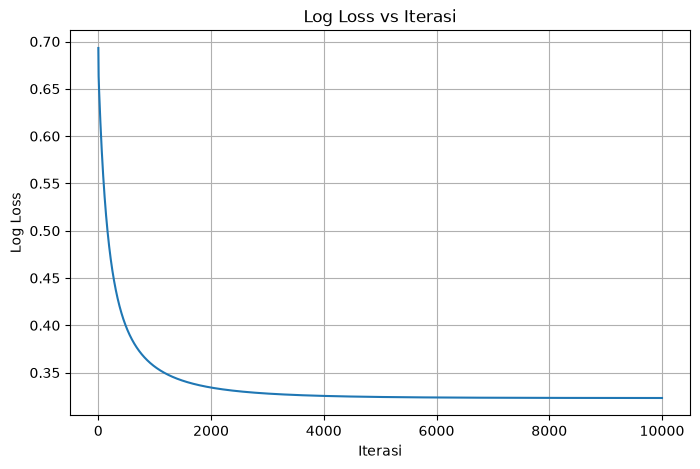

Log loss awal: 0.6931471805599452
Log loss akhir: 0.32320563059634


In [18]:
# Jawaban B2: Split Data & Training

# 1. Membagi data training dan testing
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email,
    y_email,
    test_size=0.25,
    random_state=RANDOM_STATE
)

print("Shape X_train:", X_train_email.shape)
print("Shape X_test :", X_test_email.shape)
print("Shape y_train:", y_train_email.shape)
print("Shape y_test :", y_test_email.shape)


# 2. Fungsi sigmoid
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


# 3. Fungsi Logistic Regression dengan Gradient Descent
def LogisticRegression(X, y, learning_rate=0.1, n_iterations=10000):
    X_bias = np.c_[np.ones(X.shape[0]), X]
    theta = np.zeros(X_bias.shape[1])
    losses = []

    for i in range(n_iterations):
        # Menghitung probabilitas prediksi
        z = X_bias @ theta
        prob = sigmoid(z)

        # Menghitung log loss
        eps = 1e-15
        prob_safe = np.clip(prob, eps, 1 - eps)

        loss = -np.mean(
            y * np.log(prob_safe)
            + (1 - y) * np.log(1 - prob_safe)
        )
        losses.append(loss)

        # Menghitung gradien dan memperbarui parameter
        gradient = X_bias.T @ (prob - y) / len(y)
        theta = theta - learning_rate * gradient

    return theta[0], theta[1:], losses


# 4. Melatih model
b_log, coef_log, log_losses = LogisticRegression(
    X_train_email,
    y_train_email,
    learning_rate=0.1,
    n_iterations=10000
)

# Menampilkan intercept dan koefisien
print("\nIntercept (b):", b_log)
print("Koefisien m1 (JumlahLink):", coef_log[0])
print("Koefisien m2 (KataPromo):", coef_log[1])

print(
    f"\nPersamaan model:\n"
    f"P(Spam) = sigmoid({b_log:.4f} "
    f"+ ({coef_log[0]:.4f} * JumlahLink) "
    f"+ ({coef_log[1]:.4f} * KataPromo))"
)


# 5. Membuat grafik log loss vs iterasi
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(log_losses) + 1), log_losses)
plt.title("Log Loss vs Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.grid(True)
plt.show()

print("Log loss awal:", log_losses[0])
print("Log loss akhir:", log_losses[-1])

**Jawaban B2 (analisis):**

Data email dibagi menjadi data testing sebesar 25%. Setelah itu, model Logistic Regression dilatih menggunakan Gradient Descent dengan learning rate 0,1 dan 10.000 iterasi. Model mempelajari hubungan jumlah link dan kata promosi untuk memperkirakan apakah email termasuk spam atau bukan. Grafik log loss digunakan untuk melihat perkembangan proses belajar model. Jika nilai log loss terus menurun lalu menjadi stabil, berarti model semakin baik dalam membuat prediksi. Namun, jika nilainya masih naik turun atau tidak menunjukkan penurunan, berarti proses belajarnya belum berjalan dengan baik. Hasil akhirnya bisa dilihat dari grafik dan perbandingan log loss awal dengan log loss akhir.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [20]:
# Jawaban B3

# Membuat prediksi pada data testing
X_test_bias = np.c_[np.ones(X_test_email.shape[0]), X_test_email]
prob_test = sigmoid(X_test_bias @ np.r_[b_log, coef_log])
y_pred_email = (prob_test >= 0.5).astype(int)

# Menghitung nilai TP, TN, FP, dan FN
TP = np.sum((y_test_email == 1) & (y_pred_email == 1))
TN = np.sum((y_test_email == 0) & (y_pred_email == 0))
FP = np.sum((y_test_email == 0) & (y_pred_email == 1))
FN = np.sum((y_test_email == 1) & (y_pred_email == 0))

# Confusion matrix: baris = label sebenarnya, kolom = prediksi
conf_matrix = np.array([
    [TN, FP],
    [FN, TP]
])

# Menghitung metrik evaluasi
accuracy = (TP + TN) / len(y_test_email)

precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0

f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

# Menampilkan hasil
print("Confusion Matrix:")
print(conf_matrix)
print("\nKeterangan:")
print("TN (Bukan Spam diprediksi Bukan Spam):", TN)
print("FP (Bukan Spam diprediksi Spam):", FP)
print("FN (Spam diprediksi Bukan Spam):", FN)
print("TP (Spam diprediksi Spam):", TP)

hasil_b3 = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Nilai": [accuracy, precision, recall, f1_score]
})

display(hasil_b3.round(4))

Confusion Matrix:
[[11  0]
 [ 0  4]]

Keterangan:
TN (Bukan Spam diprediksi Bukan Spam): 11
FP (Bukan Spam diprediksi Spam): 0
FN (Spam diprediksi Bukan Spam): 0
TP (Spam diprediksi Spam): 4


,Metrik,Nilai
0,Accuracy,1.0
1,Precision,1.0
2,Recall,1.0
3,F1-score,1.0


**Jawaban B3 (analisis):**

Hasil evaluasi digunakan untuk mengetahui seberapa baik model membedakan email spam dan bukan spam. Accuracy menunjukkan seberapa banyak prediksi yang benar. Precision menunjukkan ketepatan model saat menandai email sebagai spam, sedangkan recall menunjukkan seberapa banyak email spam yang berhasil ditemukan. F1-score digunakan untuk melihat keseimbangan antara precision dan recall.

FP terjadi ketika email biasa dianggap sebagai spam, sehingga email penting bisa masuk ke folder spam. Sementara itu, FN terjadi ketika email spam dianggap sebagai email biasa, sehingga spam tetap masuk ke kotak masuk. Menurut saya, FN bisa lebih berbahaya jika email spam berisi penipuan atau tautan berbahaya. Namun, FP juga bisa merugikan karena pengguna mungkin melewatkan email penting. Jadi, kedua kesalahan perlu dikurangi agar filter email bekerja dengan baik.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

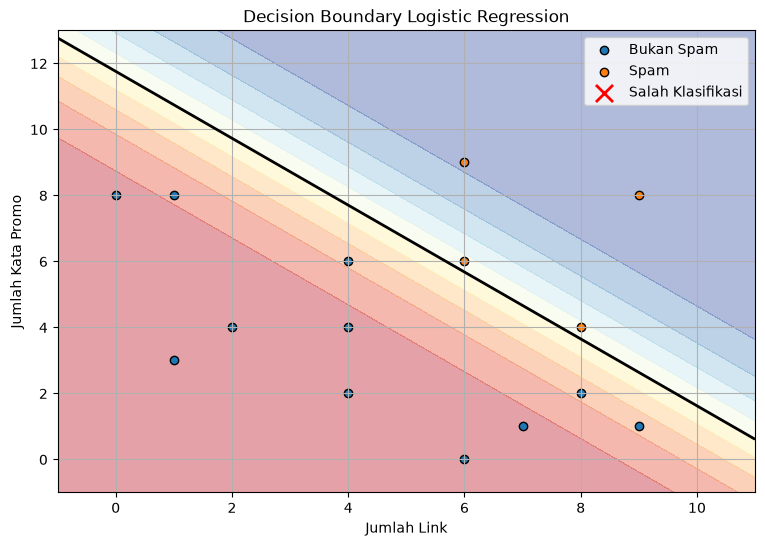

Jumlah data yang salah diklasifikasikan: 0


,JumlahLink,KataPromo,LabelSebenarnya,Prediksi,ProbabilitasSpam


In [21]:
# Jawaban B4

# Membuat area grafik
x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1

xx1, xx2 = np.meshgrid(
    np.linspace(x1_min, x1_max, 200),
    np.linspace(x2_min, x2_max, 200)
)

# Menghitung probabilitas pada setiap titik
grid = np.c_[xx1.ravel(), xx2.ravel()]
grid_bias = np.c_[np.ones(len(grid)), grid]
prob_grid = sigmoid(grid_bias @ np.r_[b_log, coef_log])
prob_grid = prob_grid.reshape(xx1.shape)

plt.figure(figsize=(9, 6))

# Background probabilitas
plt.contourf(
    xx1, xx2, prob_grid,
    levels=np.linspace(0, 1, 11),
    cmap="RdYlBu",
    alpha=0.4
)

# Garis decision boundary saat probabilitas = 0.5
plt.contour(
    xx1, xx2, prob_grid,
    levels=[0.5],
    colors="black",
    linewidths=2
)

# Menampilkan data testing
for kelas, label in [(0, "Bukan Spam"), (1, "Spam")]:
    mask = y_test_email == kelas
    plt.scatter(
        X_test_email[mask, 0],
        X_test_email[mask, 1],
        label=label,
        edgecolors="black"
    )

# Menandai data yang salah diprediksi
salah = y_pred_email != y_test_email

plt.scatter(
    X_test_email[salah, 0],
    X_test_email[salah, 1],
    marker="x",
    s=150,
    color="red",
    linewidths=2,
    label="Salah Klasifikasi"
)

plt.title("Decision Boundary Logistic Regression")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(True)
plt.show()

# Menampilkan data testing yang salah diklasifikasikan
data_salah = pd.DataFrame({
    "JumlahLink": X_test_email[salah, 0],
    "KataPromo": X_test_email[salah, 1],
    "LabelSebenarnya": y_test_email[salah],
    "Prediksi": y_pred_email[salah],
    "ProbabilitasSpam": prob_test[salah]
})

print("Jumlah data yang salah diklasifikasikan:", salah.sum())
display(data_salah)

**Jawaban B4 (analisis):**

Grafik decision boundary menunjukkan batas yang digunakan model untuk membedakan email spam dan bukan spam. Area dengan probabilitas spam 0,5 menjadi batas pemisah kedua kategori tersebut. Titik silang berwarna merah menunjukkan email yang salah diprediksi oleh model. Kesalahan ini bisa terjadi karena ciri-ciri email spam dan email biasa terkadang mirip, misalnya sama-sama memiliki link atau kata promosi. Dengan melihat grafik dan data yang salah diprediksi, bisa diketahui bagian mana yang masih sulit dibedakan oleh model. Jika masih banyak prediksi yang salah, model perlu diperbaiki atau ditambah dengan data yang lebih beragam.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [22]:
# Jawaban B5

# Menghitung probabilitas spam pada data testing
X_test_bias = np.c_[np.ones(X_test_email.shape[0]), X_test_email]
prob_test = sigmoid(X_test_bias @ np.r_[b_log, coef_log])

thresholds = [0.3, 0.5, 0.7]
hasil_threshold = []

for threshold in thresholds:
    # Menentukan prediksi berdasarkan threshold
    y_pred = (prob_test >= threshold).astype(int)

    # Menghitung TP, TN, FP, dan FN
    TP = np.sum((y_test_email == 1) & (y_pred == 1))
    TN = np.sum((y_test_email == 0) & (y_pred == 0))
    FP = np.sum((y_test_email == 0) & (y_pred == 1))
    FN = np.sum((y_test_email == 1) & (y_pred == 0))

    # Menghitung metrik
    accuracy = (TP + TN) / len(y_test_email)
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    hasil_threshold.append({
        "Threshold": threshold,
        "TN": TN,
        "FP": FP,
        "FN": FN,
        "TP": TP,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })

tabel_threshold = pd.DataFrame(hasil_threshold)
display(tabel_threshold.round(4))

,Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall,F1-score
0,0.3,11,0,0,4,1.0000,1.0,1.0,1.0000
1,0.5,11,0,0,4,1.0000,1.0,1.0,1.0000
2,0.7,11,0,2,2,0.8667,1.0,0.5,0.6667


**Jawaban B5 (analisis):**

Threshold menentukan seberapa besar kemungkinan sebuah email dianggap sebagai spam. Jika threshold diturunkan menjadi 0,3, model akan lebih mudah menandai email sebagai spam sehingga lebih banyak spam yang bisa terdeteksi, tetapi email biasa juga berisiko ikut dianggap spam. Sebaliknya, threshold 0,7 membuat model lebih selektif dalam menandai spam, sehingga email biasa lebih aman, tetapi beberapa spam bisa lolos ke kotak masuk. Threshold 0,5 berada di antara keduanya. 
Saya memilih threshold 0,5 karena berada di tengah dan merupakan nilai standar yang digunakan model Logistic Regression. Dengan threshold ini, model tidak terlalu mudah dan tidak terlalu sulit dalam menandai email sebagai spam. 

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [23]:
# Jawaban B6

# Gunakan threshold pilihan dari B5
threshold_pilihan = 0.5

# Data email baru
email_baru = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11]
})

# Mengambil fitur untuk prediksi
X_baru = email_baru[["JumlahLink", "KataPromo"]].to_numpy()

# Menghitung probabilitas spam
X_baru_bias = np.c_[np.ones(X_baru.shape[0]), X_baru]
probabilitas_spam = sigmoid(X_baru_bias @ np.r_[b_log, coef_log])

# Menentukan kelas berdasarkan threshold
prediksi_kelas = (probabilitas_spam >= threshold_pilihan).astype(int)

# Membuat tabel hasil prediksi
hasil_baru = email_baru.copy()
hasil_baru["Probabilitas Spam"] = probabilitas_spam
hasil_baru["Prediksi"] = np.where(
    prediksi_kelas == 1, "Spam", "Bukan Spam"
)

print("Threshold yang digunakan:", threshold_pilihan)
display(hasil_baru.round(4))

Threshold yang digunakan: 0.5


,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi
0,E1,1,2,0.0017,Bukan Spam
1,E2,5,6,0.3764,Bukan Spam
2,E3,9,10,0.9953,Spam
3,E4,2,11,0.7152,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression termasuk klasifikasi karena digunakan untuk menentukan kelompok data, misalnya email spam atau bukan spam. Fungsi sigmoid digunakan untuk mengubah hasil perhitungan menjadi nilai antara 0 dan 1. Nilai tersebut kemudian digunakan untuk menentukan hasil prediksi.

**Jawaban C2:** Normal Equation menghitung hasil secara langsung menggunakan perhitungan matriks, sedangkan Gradient Descent mencari hasil secara bertahap melalui beberapa proses. Normal Equation cocok ubuat data yang lebih kecil, sementara Gradient Descent digunakan buat data yang lebih besar. Tapi, Gradient Descent perlu menggunakan learning rate yang tepat agar hasilnya baik.

**Jawaban C3:** Data testing digunakan buat menguji kemampuan model dalam memprediksi data baru yang belum pernah dipelajari. Kalo hanya menggunakan data training, nantinya saya belum tahu apakah model bisa memprediksi data baru dengan baik. Overfitting terjadi saat model terlalu fokus mempelajari data training sehingga kurang baik saat menghadapi data baru.

**Jawaban C4:** Linear Regression menggunakan MSE untuk menghitung selisih antara hasil prediksi dan nilai sebenarnya. Sementara itu, Logistic Regression menggunakan log loss untuk mengukur seberapa tepat prediksi probabilitasnya. Jika model sangat yakin dengan prediksinya tetapi ternyata salah, log loss bakalan memberikan nilai kesalahan yang besar.

**Jawaban C5:** Hasil bisa berbeda karena pengaturan model yang digunakan tidak sama, misalnya random state saat membagi data training dan testing. Hasil juga bisa berbeda kalo parameter model atau proses pengolahan datanya berbeda. Karena itu, pengaturan yang digunakan harus sama jika ingin mendapatkan hasil yang bisa dibandingkan.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [24]:
# Jawaban Bonus

from sklearn.linear_model import LinearRegression as SKLinearRegression
from sklearn.linear_model import LogisticRegression as SKLogisticRegression

# ==========================================
# 1. LINEAR REGRESSION
# ==========================================

# Melatih model scikit-learn dengan data training yang sama
model_linear_sk = SKLinearRegression()
model_linear_sk.fit(X_train, y_train)

# Prediksi data testing
y_pred_sk = model_linear_sk.predict(X_test)

# Menampilkan koefisien
print("=== LINEAR REGRESSION ===")
print("Normal Equation - Intercept:", b)
print("Normal Equation - Koefisien:", m)

print("Scikit-learn - Intercept:", model_linear_sk.intercept_)
print("Scikit-learn - Koefisien:", model_linear_sk.coef_[0])

# Evaluasi model scikit-learn
hasil_linear_sk = pd.DataFrame({
    "Metrik": ["MAE", "MSE", "RMSE", "R2"],
    "Normal Equation": [
        hitung_mae(y_test, y_test_pred),
        hitung_mse(y_test, y_test_pred),
        hitung_rmse(y_test, y_test_pred),
        hitung_r2(y_test, y_test_pred)
    ],
    "Scikit-learn": [
        hitung_mae(y_test, y_pred_sk),
        hitung_mse(y_test, y_pred_sk),
        hitung_rmse(y_test, y_pred_sk),
        hitung_r2(y_test, y_pred_sk)
    ]
})

display(hasil_linear_sk.round(4))


# ==========================================
# 2. LOGISTIC REGRESSION
# ==========================================

# Melatih model scikit-learn dengan data training yang sama
model_logistic_sk = SKLogisticRegression(
    C=1.0,
    max_iter=10000,
    random_state=RANDOM_STATE
)

model_logistic_sk.fit(X_train_email, y_train_email)

# Prediksi kelas dan probabilitas pada data testing
y_pred_log_sk = model_logistic_sk.predict(X_test_email)
prob_log_sk = model_logistic_sk.predict_proba(X_test_email)[:, 1]

# Menampilkan parameter model
print("\n=== LOGISTIC REGRESSION ===")
print("Gradient Descent - Intercept:", b_log)
print("Gradient Descent - Koefisien:", coef_log)

print("Scikit-learn - Intercept:", model_logistic_sk.intercept_[0])
print("Scikit-learn - Koefisien:", model_logistic_sk.coef_[0])

# Evaluasi model manual
def evaluasi_klasifikasi(y_asli, y_pred):
    tp = np.sum((y_asli == 1) & (y_pred == 1))
    tn = np.sum((y_asli == 0) & (y_pred == 0))
    fp = np.sum((y_asli == 0) & (y_pred == 1))
    fn = np.sum((y_asli == 1) & (y_pred == 0))

    acc = (tp + tn) / len(y_asli)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = (
        2 * prec * rec / (prec + rec)
        if (prec + rec) > 0 else 0
    )

    return acc, prec, rec, f1, tn, fp, fn, tp


# Hasil model Gradient Descent buatan sendiri
hasil_manual = evaluasi_klasifikasi(
    y_test_email, y_pred_email
)

# Hasil model scikit-learn
hasil_sk = evaluasi_klasifikasi(
    y_test_email, y_pred_log_sk
)

hasil_logistic_sk = pd.DataFrame({
    "Metrik": [
        "Accuracy", "Precision", "Recall", "F1-score",
        "TN", "FP", "FN", "TP"
    ],
    "Gradient Descent": list(hasil_manual),
    "Scikit-learn": list(hasil_sk)
})

display(hasil_logistic_sk.round(4))

=== LINEAR REGRESSION ===
Normal Equation - Intercept: 29.324221482434798
Normal Equation - Koefisien: 9.005114151035892
Scikit-learn - Intercept: 29.324221482434524
Scikit-learn - Koefisien: 9.005114151035926


,Metrik,Normal Equation,Scikit-learn
0,MAE,6.3949,6.3949
1,MSE,54.5504,54.5504
2,RMSE,7.3858,7.3858
3,R2,0.8152,0.8152



=== LOGISTIC REGRESSION ===
Gradient Descent - Intercept: -8.557102632610691
Gradient Descent - Koefisien: [0.73739097 0.72755405]
Scikit-learn - Intercept: -7.957660883060419
Scikit-learn - Koefisien: [0.68061021 0.67898544]


,Metrik,Gradient Descent,Scikit-learn
0,Accuracy,1.0,1.0
1,Precision,1.0,1.0
2,Recall,1.0,1.0
3,F1-score,1.0,1.0
4,TN,11.0,11.0
5,FP,0.0,0.0
6,FN,0.0,0.0
7,TP,4.0,4.0


**Jawaban Bonus (analisis):**

Hasil Linear Regression dari Scikit-Learn hampir sama dengan metode Normal Equation karena keduanya digunakan untuk mencari garis prediksi terbaik. Sementara itu, hasil Logistic Regression bisa berbeda karena cara menghitung dan proses belajarnya tidak sama. Scikit-Learn juga memiliki regularisasi yang membantu agar model tidak terlalu bergantung pada data training. Jadi, meskipun menggunakan dataset yang sama, hasil kedua model bisa sedikit berbeda.